# Capítulo 11 · Probabilidade: caderno complementar
*Ciência de Dados e Inteligência Artificial em Saúde, Volume 1*

> **Este caderno acompanha o capítulo do livro; não o reproduz.** Definições, deduções e explicações estão no livro. Aqui você executa os cálculos do caso e confere os números. Todos os dados são **sintéticos** e os valores têm apenas finalidade didática; não possuem correlação com o mundo real.

A **Parte A** percorre o caso do capítulo, o registro de partos de uma maternidade pública, pelas seis perguntas do comitê. A **Parte B** traz o código e o resultado de cada um dos doze exercícios do capítulo (os enunciados estão no livro). Execute as células em ordem. As saídas do código usam ponto decimal.

## Parte A. O caso

**Dados.** `data/deliveries.csv`: 5.000 linhas, uma por parto, e quatro colunas: `delivery_id`, `cesarean`, `hemorrhage`, `infection` (sim/não, escritos `yes`/`no`). As seis seções a seguir seguem as perguntas do comitê, na ordem do capítulo.

As cinco primeiras linhas do registro:

In [1]:
import pandas as pd

register = pd.read_csv("data/deliveries.csv")
rows, columns = register.shape
print("O registro tem", rows, "linhas (uma por parto) e", columns, "colunas.")
register.head()

O registro tem 5000 linhas (uma por parto) e 4 colunas.


,delivery_id,cesarean,hemorrhage,infection
0,D0001,no,no,no
1,D0002,no,no,no
2,D0003,yes,no,no
3,D0004,no,no,no
4,D0005,yes,no,no


### P1. Que fração dos partos foi cesárea e que fração teve hemorragia?

O registro tem 5000 partos.
Dos 5000 partos, 1313 foram cesáreas e 3687 não.
Cesárea: 1313 de 5000 partos = 26.26 %
Hemorragia: 290 de 5000 partos = 5.8 %
Após 10 linhas: 5 cesáreas = 0.5
Após 50 linhas: 19 cesáreas = 0.38
Após 100 linhas: 27 cesáreas = 0.27
Após 500 linhas: 123 cesáreas = 0.246
Após 1000 linhas: 246 cesáreas = 0.246
Após 5000 linhas: 1313 cesáreas = 0.2626


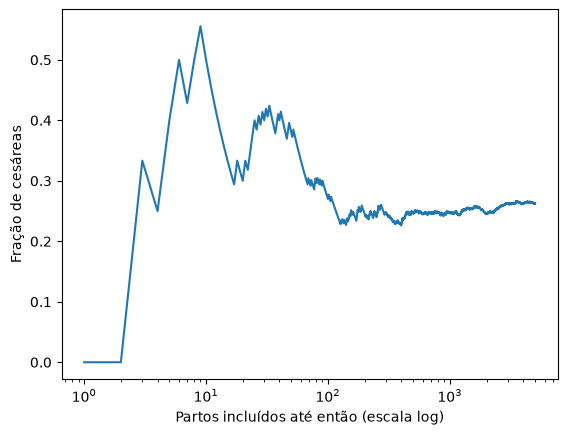

In [2]:
import pandas as pd

df = pd.read_csv("data/deliveries.csv")

# 1. Pegar todas as linhas: cada linha é um parto
n = len(df)
print("O registro tem", n, "partos.")

# 2. Em cada linha, olhar a coluna: está "yes"?
C = df["cesarean"] == "yes"        # True para cada parto cesárea
H = df["hemorrhage"] == "yes"
I = df["infection"] == "yes"
n_cesarean = C.sum()
print("Dos", n, "partos,", n_cesarean, "foram cesáreas e", n - n_cesarean, "não.")

# 3. Contar as linhas "yes" e dividir por todas as linhas
n_hemorrhage = H.sum()
print("Cesárea:", n_cesarean, "de", n, "partos =", round(100 * n_cesarean / n, 2), "%")
print("Hemorragia:", n_hemorrhage, "de", n, "partos =", round(100 * n_hemorrhage / n, 2), "%")

# 4. Ler o registro em ordem: a fração de cesáreas se estabiliza?
for k in [10, 50, 100, 500, 1000, 5000]:
    first_k = C.iloc[:k]           # as k primeiras linhas
    print("Após", k, "linhas:", first_k.sum(), "cesáreas =", round(first_k.mean(), 4))

import matplotlib.pyplot as plt

running = C.expanding().mean()        # fração de cesáreas entre as linhas lidas até agora
plt.plot(range(1, n + 1), running)
plt.xscale("log")
plt.xlabel("Partos incluídos até então (escala log)")
plt.ylabel("Fração de cesáreas")
plt.show()

### P2. Quantas mães tiveram hemorragia ou infecção?

In [3]:
# 1. Cruzar as duas colunas: cada parto cai em exatamente uma de quatro células
print("Hemorragia (linhas) por infecção (colunas):")
print(pd.crosstab(df["hemorrhage"], df["infection"], margins=True, margins_name="Total"))

# 2. Somar os dois grupos e corrigir as mães contadas duas vezes
n_hemorrhage = H.sum()
n_infection = I.sum()
n_both = (H & I).sum()             # "&" significa "e": as duas ao mesmo tempo
print()
print(n_hemorrhage, "mães tiveram hemorragia e", n_infection, "tiveram infecção.")
print("Somando as duas dá", n_hemorrhage + n_infection, "mas as", n_both, "mães com ambas foram contadas duas vezes.")
print("Hemorragia ou infecção:", n_hemorrhage, "+", n_infection, "-", n_both, "=", n_hemorrhage + n_infection - n_both, "mães.")

# 3. Conferir contando diretamente e contar as mães sem nenhuma das duas
either = H | I                     # "|" significa "ou": ao menos uma das duas
n_either = either.sum()
print()
print("Contando direto:", n_either, "de", n, "mães =", round(100 * n_either / n, 2), "%")
print("Sem nenhuma:", n - n_either, "de", n, "mães =", round(100 * (n - n_either) / n, 2), "%")

Hemorragia (linhas) por infecção (colunas):
infection     no  yes  Total
hemorrhage                  
no          4599  111   4710
yes          271   19    290
Total       4870  130   5000

290 mães tiveram hemorragia e 130 tiveram infecção.
Somando as duas dá 420 mas as 19 mães com ambas foram contadas duas vezes.
Hemorragia ou infecção: 290 + 130 - 19 = 401 mães.

Contando direto: 401 de 5000 mães = 8.02 %
Sem nenhuma: 4599 de 5000 mães = 91.98 %


### P3. A infecção é mais frequente após cesárea?

In [4]:
# 1. Separar os partos por tipo: cesárea e vaginal (não cesárea)
n_cesarean = C.sum()
n_vaginal = (~C).sum()             # "~" significa "não"

# 2. Dentro de cada grupo, contar as infecções e dividir pelo tamanho desse grupo
infected_cesarean = (C & I).sum()
infected_vaginal = (~C & I).sum()
print("Infecção entre os partos cesárea:", infected_cesarean, "de", n_cesarean, "=", round(infected_cesarean / n_cesarean, 4))
print("Infecção entre os partos vaginais:", infected_vaginal, "de", n_vaginal, "=", round(infected_vaginal / n_vaginal, 4))

# 3. As mesmas 87 cesáreas infectadas sobre TODOS os partos (outro denominador)
print()
print("Cesárea e infecção, entre todos os partos:", infected_cesarean, "de", n, "=", round(infected_cesarean / n, 4))

# 4. Infecção sobre todos os partos, qualquer que seja o tipo
print("Infecção, entre todos os partos:", I.sum(), "de", n, "=", round(I.sum() / n, 4))

Infecção entre os partos cesárea: 87 de 1313 = 0.0663
Infecção entre os partos vaginais: 43 de 3687 = 0.0117

Cesárea e infecção, entre todos os partos: 87 de 5000 = 0.0174
Infecção, entre todos os partos: 130 de 5000 = 0.026


### P4. Hemorragia e infecção vêm juntas ou de modo independente?

In [5]:
# 1. Se hemorragia e infecção fossem independentes, P(H e I) seria igual a P(H) x P(I)
p_h = H.sum() / n
p_i = I.sum() / n
print("Esperado se independentes:", round(p_h, 4), "x", round(p_i, 4), "=", round(p_h * p_i, 6))

# 2. O que o registro mostra
n_both = (H & I).sum()
print("Observado, as duas juntas:", n_both, "de", n, "=", round(n_both / n, 4))

# 3. Infecção entre as mães com e sem hemorragia
print()
print("Infecção entre as mães com hemorragia:", n_both, "de", H.sum(), "=", round(n_both / H.sum(), 4))
print("Infecção entre as mães sem hemorragia:", (~H & I).sum(), "de", (~H).sum(), "=", round((~H & I).sum() / (~H).sum(), 4))

# 4. Multiplicar mantendo as condições: cesárea, depois hemorragia, depois infecção
n_c, n_ch, n_chi = C.sum(), (C & H).sum(), (C & H & I).sum()
print()
print("De", n_c, "cesáreas,", n_ch, "tiveram hemorragia, e", n_chi, "delas também tiveram infecção.")
chain = (n_c / n) * (n_ch / n_c) * (n_chi / n_ch)
print("P(C) x P(H|C) x P(I|C e H) =", round(chain, 4), "; contagem direta:", round(n_chi / n, 4))

Esperado se independentes: 0.058 x 0.026 = 0.001508
Observado, as duas juntas: 19 de 5000 = 0.0038

Infecção entre as mães com hemorragia: 19 de 290 = 0.0655
Infecção entre as mães sem hemorragia: 111 de 4710 = 0.0236

De 1313 cesáreas, 95 tiveram hemorragia, e 14 delas também tiveram infecção.
P(C) x P(H|C) x P(I|C e H) = 0.0028 ; contagem direta: 0.0028


### P5. Entre as mães com infecção, que fração teve cesárea?

In [6]:
# 1. A tabela: linhas são o tipo de parto, colunas são a infecção
print("Tipo de parto (linhas) por infecção (colunas):")
print(pd.crosstab(df["cesarean"], df["infection"], margins=True, margins_name="Total"))

# 2. Reconstruir a fração geral de infecção a partir dos dois grupos
p_c = C.sum() / n                                  # P(C)
p_i_given_c = (C & I).sum() / C.sum()              # P(I|C)
p_i_given_not_c = (~C & I).sum() / (~C).sum()      # P(I|não C)
p_i = p_i_given_c * p_c + p_i_given_not_c * (1 - p_c)
print()
print("P(I) = P(I|C) P(C) + P(I|não C) P(não C) =", round(p_i, 4))

# 3. Inverter a condição (Bayes): da infecção entre as cesáreas para as cesáreas entre as infecções
p_c_given_i = p_i_given_c * p_c / p_i
print("P(C|I) = P(I|C) P(C) / P(I) =", round(p_c_given_i, 4))

# 4. Conferir contando diretamente entre as mães infectadas
print("Contando direto:", (C & I).sum(), "das", I.sum(), "infecções vieram depois de cesárea =", round(100 * (C & I).sum() / I.sum(), 2), "%")

Tipo de parto (linhas) por infecção (colunas):
infection    no  yes  Total
cesarean                   
no         3644   43   3687
yes        1226   87   1313
Total      4870  130   5000

P(I) = P(I|C) P(C) + P(I|não C) P(não C) = 0.026
P(C|I) = P(I|C) P(C) / P(I) = 0.6692
Contando direto: 87 das 130 infecções vieram depois de cesárea = 66.92 %


### P6. De quantas maneiras se escolhem 20 prontuários e qual a chance de a amostra incluir uma infecção?

In [7]:
from math import comb, factorial, perm

total = n                          # prontuários no registro
with_infection = I.sum()           # prontuários com infecção

# 1. De quantas maneiras se escolhem 20 prontuários? (a ordem não importa)
sets = comb(total, 20)
print("Há", sets, "conjuntos diferentes de 20 prontuários,", len(str(sets)), "algarismos.")

# 2. Ordens dos 20 prontuários escolhidos, e dos dois primeiros lugares
print("Os 20 prontuários escolhidos podem ser postos em", factorial(20), "ordens; os dois primeiros lugares, em", perm(20, 2))

# 3. Chance de ao menos uma infecção = 1 - chance de nenhuma (os 20 entre os prontuários sem infecção)
without_infection = total - with_infection
chance_none = comb(without_infection, 20) / comb(total, 20)
print()
print("Chance de 20 prontuários incluírem ao menos uma infecção:", round(1 - chance_none, 4))

# 4. Menor amostra com ao menos 90%: testar tamanhos 1, 2, 3, ... até a chance de nenhuma ser no máximo 10%
size = 1
while 10 * comb(without_infection, size) > comb(total, size):     # compara números inteiros, sem arredondar
    size = size + 1
for m in [size - 1, size]:
    print("Com", m, "prontuários a chance é", round(1 - comb(without_infection, m) / comb(total, m), 6))
print("Logo", size, "é a menor amostra com ao menos 90%.")

Há 37735558620382470911680923426535607627307325009655406000 conjuntos diferentes de 20 prontuários, 56 algarismos.
Os 20 prontuários escolhidos podem ser postos em 2432902008176640000 ordens; os dois primeiros lugares, em 380

Chance de 20 prontuários incluírem ao menos uma infecção: 0.4102
Com 86 prontuários a chance é 0.898259
Com 87 prontuários a chance é 0.90095
Logo 87 é a menor amostra com ao menos 90%.


## Parte B. Soluções dos exercícios

### Exercício 1. Registros e descrições de eventos

In [8]:
from itertools import product

# 1. O espaço amostral: um dos 5.000 identificadores
print(n, "registros,", df["delivery_id"].nunique(), "identificadores distintos.")

# 2. As oito descrições (C, H, I), 1 = sim e 0 = não
print("As oito descrições:")
for bits in product([0, 1], repeat=3):
    print(bits)

5000 registros, 5000 identificadores distintos.
As oito descrições:
(0, 0, 0)
(0, 0, 1)
(0, 1, 0)
(0, 1, 1)
(1, 0, 0)
(1, 0, 1)
(1, 1, 0)
(1, 1, 1)


### Exercício 2. Frações acumuladas e ordem

In [9]:
# 1. Fração de cesáreas entre os k primeiros registros
for k in [10, 50, 100, 500, 1000, 5000]:
    print("Primeiros", k, "registros:", round(C.iloc[:k].mean(), 4))

# 2. Inverter a ordem do registro: primeiros 100 registros e todos os 5.000
reverse = C.iloc[::-1]             # as mesmas linhas, da última para a primeira
print()
print("Ordem invertida: primeiros 100 registros", round(reverse.iloc[:100].mean(), 4), "; todos os", n, "registros", round(reverse.mean(), 4))

Primeiros 10 registros: 0.5
Primeiros 50 registros: 0.38
Primeiros 100 registros: 0.27
Primeiros 500 registros: 0.246
Primeiros 1000 registros: 0.246
Primeiros 5000 registros: 0.2626

Ordem invertida: primeiros 100 registros 0.25 ; todos os 5000 registros 0.2626


### Exercício 3. Contar a sobreposição uma vez

In [10]:
# 1. Os quatro grupos: só hemorragia, só infecção, ambas, nenhuma
only_h = (H & ~I).sum()
only_i = (~H & I).sum()
both = (H & I).sum()
neither = (~H & ~I).sum()
print("Só hemorragia:", only_h, "mães =", round(only_h / n, 4))
print("Só infecção:", only_i, "mães =", round(only_i / n, 4))
print("Ambas:", both, "mães =", round(both / n, 4))
print("Nenhuma:", neither, "mães =", round(neither / n, 4))

# 2. Regra da adição, e a mesma contagem feita diretamente
print()
print("Regra da adição:", H.sum() + I.sum() - both, "mães com hemorragia ou infecção =", round((H.sum() + I.sum() - both) / n, 4))
print("Contagem direta:", (H | I).sum(), "mães")

Só hemorragia: 271 mães = 0.0542
Só infecção: 111 mães = 0.0222
Ambas: 19 mães = 0.0038
Nenhuma: 4599 mães = 0.9198

Regra da adição: 401 mães com hemorragia ou infecção = 0.0802
Contagem direta: 401 mães


### Exercício 4. Nomear o denominador

In [11]:
# 1. As cinco frações: o numerador e o denominador de cada uma
print("(a) infecção entre as cesáreas:", (C & I).sum(), "/", C.sum(), "=", round((C & I).sum() / C.sum(), 4))
print("(b) cesárea e infecção, entre todos:", (C & I).sum(), "/", n, "=", round((C & I).sum() / n, 4))
print("(c) infecção, entre todos:", I.sum(), "/", n, "=", round(I.sum() / n, 4))
print("(d) cesárea entre as infecções:", (C & I).sum(), "/", I.sum(), "=", round((C & I).sum() / I.sum(), 4))
print("(e) hemorragia entre as cesáreas:", (C & H).sum(), "/", C.sum(), "=", round((C & H).sum() / C.sum(), 4))

(a) infecção entre as cesáreas: 87 / 1313 = 0.0663
(b) cesárea e infecção, entre todos: 87 / 5000 = 0.0174
(c) infecção, entre todos: 130 / 5000 = 0.026
(d) cesárea entre as infecções: 87 / 130 = 0.6692
(e) hemorragia entre as cesáreas: 95 / 1313 = 0.0724


### Exercício 5. Comparar dentro dos tipos de parto

In [12]:
# 1. Infecção em cada tipo de parto, e a razão das duas proporções
p_cesarean = (C & I).sum() / C.sum()
p_vaginal = (~C & I).sum() / (~C).sum()
print("Infecção: cesárea", round(p_cesarean, 4), "versus vaginal", round(p_vaginal, 4), "; razão", round(p_cesarean / p_vaginal, 4))

# 2. Hemorragia em cada tipo de parto: contagem, tamanho do grupo, proporção
print("Hemorragia, cesárea:", (C & H).sum(), "de", C.sum(), "=", round((C & H).sum() / C.sum(), 4))
print("Hemorragia, vaginal:", (~C & H).sum(), "de", (~C).sum(), "=", round((~C & H).sum() / (~C).sum(), 4))

Infecção: cesárea 0.0663 versus vaginal 0.0117 ; razão 5.6815
Hemorragia, cesárea: 95 de 1313 = 0.0724
Hemorragia, vaginal: 195 de 3687 = 0.0529


### Exercício 6. Dependência e sobreposição

In [13]:
# 1. Produto das marginais versus a fração conjunta observada
p_h, p_i = H.sum() / n, I.sum() / n
print("Produto das marginais:", round(p_h * p_i, 6), "; fração conjunta observada:", round((H & I).sum() / n, 4))

# 2. Infecção com e sem hemorragia, e o número com ambas
print("Infecção com hemorragia:", round((H & I).sum() / H.sum(), 4), "; sem hemorragia:", round((~H & I).sum() / (~H).sum(), 4))
print("Mães com ambas:", (H & I).sum())

Produto das marginais: 0.001508 ; fração conjunta observada: 0.0038
Infecção com hemorragia: 0.0655 ; sem hemorragia: 0.0236
Mães com ambas: 19


### Exercício 7. Dois caminhos para a mesma probabilidade conjunta

In [14]:
# 1. As contagens pelo caminho
n_c, n_h, n_ch, n_chi = C.sum(), H.sum(), (C & H).sum(), (C & H & I).sum()
print("Contagens:", n_c, "cesáreas,", n_h, "hemorragias,", n_ch, "com ambas,", n_chi, "com as três.")

# 2. Duas ordens para as condições: C, H, I e H, C, I (devem coincidir)
first = (n_c / n) * (n_ch / n_c) * (n_chi / n_ch)
second = (n_h / n) * (n_ch / n_h) * (n_chi / n_ch)
print("Caminho C, H, I:", round(first, 4), "| caminho H, C, I:", round(second, 4), "| contagem direta:", round(n_chi / n, 4))

Contagens: 1313 cesáreas, 290 hemorragias, 95 com ambas, 14 com as três.
Caminho C, H, I: 0.0028 | caminho H, C, I: 0.0028 | contagem direta: 0.0028


### Exercício 8. Probabilidade total e inversão

In [15]:
# 1. Probabilidade total de infecção a partir dos dois tipos de parto
p_c = C.sum() / n
p_i_given_c = (C & I).sum() / C.sum()
p_i_given_not_c = (~C & I).sum() / (~C).sum()
p_i = p_i_given_c * p_c + p_i_given_not_c * (1 - p_c)
print("Probabilidade total de infecção:", round(p_i, 4))

# 2. Bayes: cesáreas entre as infectadas e partos vaginais entre as infectadas
bayes = p_i_given_c * p_c / p_i
print("Entre as infectadas: cesárea", round(bayes, 4), "; vaginal", round(1 - bayes, 4))
print("Contagem direta entre as infectadas: cesárea", round((C & I).sum() / I.sum(), 4))

Probabilidade total de infecção: 0.026
Entre as infectadas: cesárea 0.6692 ; vaginal 0.3308
Contagem direta entre as infectadas: cesárea 0.6692


### Exercício 9. Ordens dos prontuários selecionados

In [16]:
from math import factorial, perm

# 1. Ordens de 20 prontuários, e dois primeiros lugares ordenados
print("20! =", factorial(20), "ordens; dois primeiros lugares:", perm(20, 2), "escolhas ordenadas")

# 2. Chance de um prontuário dado ser o primeiro, e de dois dados serem o primeiro e o segundo
print("Um prontuário dado é o primeiro com chance", round(factorial(19) / factorial(20), 4))
print("Dois prontuários dados são o primeiro e o segundo com chance", round(factorial(18) / factorial(20), 6))

20! = 2432902008176640000 ordens; dois primeiros lugares: 380 escolhas ordenadas
Um prontuário dado é o primeiro com chance 0.05
Dois prontuários dados são o primeiro e o segundo com chance 0.002632


### Exercício 10. Uma amostra que inclui uma infecção

In [17]:
from math import comb

total, without_infection = n, n - I.sum()

# 1. Menor amostra com ao menos 90% de chance de incluir uma infecção
size = 1
while 10 * comb(without_infection, size) > comb(total, size):
    size = size + 1

# 2. A chance para uma amostra de 20, para o tamanho logo abaixo e para o menor tamanho
for m in [20, size - 1, size]:
    print(m, "prontuários: chance de ao menos uma infecção =", round(1 - comb(without_infection, m) / comb(total, m), 6))

20 prontuários: chance de ao menos uma infecção = 0.410156
86 prontuários: chance de ao menos uma infecção = 0.898259
87 prontuários: chance de ao menos uma infecção = 0.90095


### Exercício 11. Probabilidades marginais alternativas (alt.)

In [18]:
# 1. Marginais alternativas: P(H) = 0,02 e P(I) = 0,03
p_h = 0.02
p_i = 0.03

# 2. Menor e maior probabilidade conjunta possível, e P(H ou I) se independentes
lower = max(p_h, p_i)
upper = min(1, p_h + p_i)
print("A probabilidade conjunta deve estar entre", lower, "e", upper)
print("Se os eventos fossem independentes, P(H ou I) =", round(p_h + p_i - p_h * p_i, 4))

A probabilidade conjunta deve estar entre 0.03 e 0.05
Se os eventos fossem independentes, P(H ou I) = 0.0494


### Exercício 12. Devolver prontuários entre sorteios (alt.)

In [19]:
from math import comb

total, without_infection = n, n - I.sum()

# 1. Chance de ao menos uma infecção em 20 sorteios, com e sem devolver o prontuário
with_replacement = 1 - (without_infection / total) ** 20
without_replacement = 1 - comb(without_infection, 20) / comb(total, 20)
print("Devolvendo cada prontuário:", round(with_replacement, 6), "| sem devolver:", round(without_replacement, 6))

# 2. A diferença entre os dois procedimentos
print("A diferença é de apenas", round(without_replacement - with_replacement, 6))

Devolvendo cada prontuário: 0.409555 | sem devolver: 0.410156
A diferença é de apenas 0.0006


---
*Dados sintéticos (semente 11, `generate_data.py`). Valores apenas didáticos; nada aqui é recomendação clínica nem estimativa para uma unidade real.*